# 03 · Feature engineering
**Owner:** Dhanvin Vadlamudi

Two kinds of features:
* **TF-IDF** on the premise and hypothesis text
* **Structured** features from the parsed facts and the PC graph (notebook 02)

TF-IDF and the scaler are fitted on train only. Test is not used here.
The structured features are built in `src/c2c/features.py` and tested in `tests/test_features.py`.

In [1]:
# ─── IMPORTS ─────
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

sys.path.insert(0, "../src")
from c2c.features import FEATURES, add_claim_type, add_premise_facts, add_graph_facts

In [2]:
# ─── LOAD DATA ─────
data = pd.read_csv("../data/processed/parsed.csv")
graphs = pd.read_csv("../data/processed/premise_graphs.csv").fillna("")

data = data.merge(graphs[["premise_id", "directed_edges", "undirected_edges", "mec_size"]], on="premise_id")
data.head()

,premise_id,split,premise,hypothesis,label,num_variables,template,x,y,relation,variables,mec_support,directed_edges,undirected_edges,mec_size
0,18,train,Suppose there is a closed system of 5 variable...,E directly causes B.,0,5,child,E,B,direct_cause,"A, B, C, D, E",0.0,A->E;B->E;C->E;D->E,A-B;A-C;A-D,4
1,25,train,Suppose there is a closed system of 5 variable...,"E is a cause for D, but not a direct one.",0,5,non-child descendant,E,D,indirect_cause,"A, B, C, D, E",0.0,A->C;A->D;B->C;B->D;C->E,C-D,2
2,25,train,Suppose there is a closed system of 5 variable...,E directly causes D.,0,5,child,E,D,direct_cause,"A, B, C, D, E",0.0,A->C;A->D;B->C;B->D;C->E,C-D,2
3,25,train,Suppose there is a closed system of 5 variable...,D causes something else which causes E.,0,5,non-parent ancestor,D,E,indirect_cause,"A, B, C, D, E",0.5,A->C;A->D;B->C;B->D;C->E,C-D,2
4,25,train,Suppose there is a closed system of 5 variable...,D directly causes E.,0,5,parent,D,E,direct_cause,"A, B, C, D, E",0.0,A->C;A->D;B->C;B->D;C->E,C-D,2


In [3]:
# ─── STEP 1: CLAIM TYPE ─────
# one-hot encode the relation (the types have no order, so no label encoding)
data = add_claim_type(data)
data[["relation", "rel_collider", "rel_confounder", "rel_direct_cause", "rel_indirect_cause"]].head()

,relation,rel_collider,rel_confounder,rel_direct_cause,rel_indirect_cause
0,direct_cause,0,0,1,0
1,indirect_cause,0,0,0,1
2,direct_cause,0,0,1,0
3,indirect_cause,0,0,0,1
4,direct_cause,0,0,1,0


In [4]:
# ─── STEP 2: WHAT THE PREMISE SAYS ─────
# counts of correlations and independences, and what the premise says about the pair X, Y of the hypothesis
data = add_premise_facts(data)
data[["hypothesis", "xy_correlated", "xy_independent", "xy_independent_given"]].head()

,hypothesis,xy_correlated,xy_independent,xy_independent_given
0,E directly causes B.,1,0,0
1,"E is a cause for D, but not a direct one.",1,0,1
2,E directly causes D.,1,0,1
3,D causes something else which causes E.,1,0,1
4,D directly causes E.,1,0,1


In [5]:
# ─── STEP 3: WHAT THE PC GRAPH SAYS ─────
# which way PC points the X-Y edge, and the log of how many DAGs fit the premise
data = add_graph_facts(data)
data[["hypothesis", "directed_edges", "edge_x_to_y", "edge_y_to_x", "edge_undirected", "mec_support"]].head()

,hypothesis,directed_edges,edge_x_to_y,edge_y_to_x,edge_undirected,mec_support
0,E directly causes B.,A->E;B->E;C->E;D->E,0,1,0,0.0
1,"E is a cause for D, but not a direct one.",A->C;A->D;B->C;B->D;C->E,0,0,0,0.0
2,E directly causes D.,A->C;A->D;B->C;B->D;C->E,0,0,0,0.0
3,D causes something else which causes E.,A->C;A->D;B->C;B->D;C->E,0,0,0,0.5
4,D directly causes E.,A->C;A->D;B->C;B->D;C->E,0,0,0,0.0


In [6]:
# the 15 structured features (FEATURES comes from src/c2c/features.py)
train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]
y_train = train["label"]
y_val = validation["label"]

train[FEATURES].describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
num_variables,5.96,5.0,6.00
n_correlations,12.84,0.0,15.00
n_independencies,37.56,2.0,240.00
rel_collider,0.17,0.0,1.00
rel_confounder,0.17,0.0,1.00
rel_direct_cause,0.33,0.0,1.00
rel_indirect_cause,0.33,0.0,1.00
xy_correlated,0.87,0.0,1.00
xy_independent,0.13,0.0,1.00
xy_independent_given,0.42,0.0,1.00


In [7]:
train[FEATURES].isnull().sum().sum()

np.int64(0)

No missing values, so no imputation. The columns are on different scales, so we standardise them.

In [8]:
# ─── STEP 4: TF-IDF (fit on train, transform validation) ─────
# token_pattern keeps one-letter words, because A, B, C are the variable names
tfidf_premise = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_premise = tfidf_premise.fit_transform(train["premise"]).toarray()
X_val_premise = tfidf_premise.transform(validation["premise"]).toarray()

tfidf_hypothesis = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_hypothesis = tfidf_hypothesis.fit_transform(train["hypothesis"]).toarray()
X_val_hypothesis = tfidf_hypothesis.transform(validation["hypothesis"]).toarray()

print(X_train_premise.shape, X_train_hypothesis.shape)

(35340, 135) (35340, 106)


In [9]:
# ─── STEP 5: SCALE THE STRUCTURED FEATURES ─────
scaler = StandardScaler()
X_train_structured = scaler.fit_transform(train[FEATURES])
X_val_structured = scaler.transform(validation[FEATURES])

In [10]:
# ─── STEP 6: FEATURE SELECTION ─────
# top TF-IDF terms by chi-squared
scores, p_values = chi2(X_train_premise, y_train)
pd.Series(scores, index=tfidf_premise.get_feature_names_out()).sort_values(ascending=False).head(10)

a e        90.733192
given f    90.293612
b e        87.844628
of f       86.006943
f a        79.725059
c e        65.507540
and b      60.884782
b b        50.547734
given e    43.836138
c is       34.286679
dtype: float64

In [11]:
scores, p_values = chi2(X_train_hypothesis, y_train)
pd.Series(scores, index=tfidf_hypothesis.get_feature_names_out()).sort_values(ascending=False).head(10)

causes b         304.074207
causes a         304.002886
causes f         284.418729
f directly       244.226358
effect of        235.847488
effect           235.847488
one collider     235.847488
common effect    235.847488
collider         235.847488
collider i       235.847488
dtype: float64

The top terms are claim types ("collider") and variable letters. They don't link the hypothesis to what the
premise says about that pair, which is the reasoning we need.

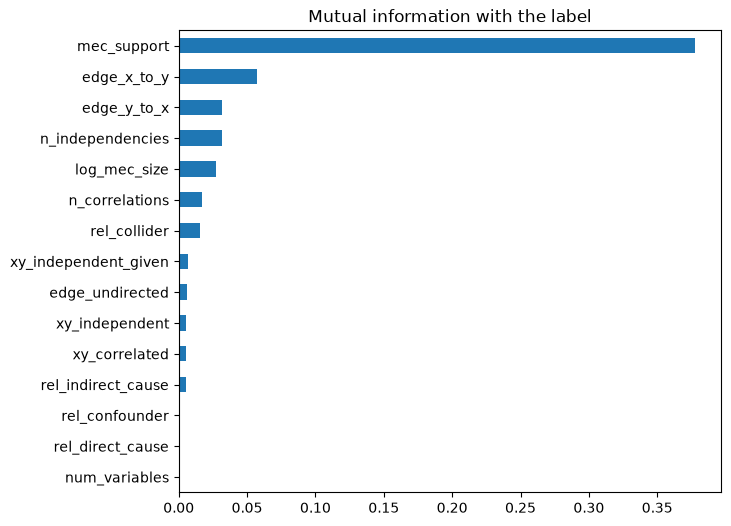

In [12]:
# structured features by mutual information
# the 0/1 and count columns are discrete; only log_mec_size and mec_support are continuous
discrete = [feature not in ["log_mec_size", "mec_support"] for feature in FEATURES]
mi = mutual_info_classif(train[FEATURES], y_train, discrete_features=discrete, random_state=42)
pd.Series(mi, index=FEATURES).sort_values().plot(kind="barh", figsize=(7, 6), title="Mutual information with the label")
plt.savefig("../report/figures/mutual_information.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# does keeping only the top TF-IDF terms help?
select_premise = SelectKBest(chi2, k=50)
X_train_premise_top = select_premise.fit_transform(X_train_premise, y_train)
X_val_premise_top = select_premise.transform(X_val_premise)

select_hypothesis = SelectKBest(chi2, k=30)
X_train_hypothesis_top = select_hypothesis.fit_transform(X_train_hypothesis, y_train)
X_val_hypothesis_top = select_hypothesis.transform(X_val_hypothesis)

X_train_all = np.hstack([X_train_premise, X_train_hypothesis, X_train_structured])
X_val_all = np.hstack([X_val_premise, X_val_hypothesis, X_val_structured])
X_train_top = np.hstack([X_train_premise_top, X_train_hypothesis_top, X_train_structured])
X_val_top = np.hstack([X_val_premise_top, X_val_hypothesis_top, X_val_structured])

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_all, y_train)
print("all terms     F1:", f1_score(y_val, model.predict(X_val_all)))

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_top, y_train)
print("top 50 + 30   F1:", f1_score(y_val, model.predict(X_val_top)))

all terms     F1: 0.8837209302325582
top 50 + 30   F1: 0.9029850746268657


Keeping only the top terms changes F1 by about 0.02 (0.884 vs 0.903). The vocabulary is already small (241 terms)
and the validation set has only 19 premises, so this gap is within the noise. We keep all terms for simplicity.

In [14]:
# ─── STEP 7: TF-IDF vs STRUCTURED vs BOTH ─────
X_train_text = np.hstack([X_train_premise, X_train_hypothesis])
X_val_text = np.hstack([X_val_premise, X_val_hypothesis])

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_text, y_train)
pred_text = model.predict(X_val_text)

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_structured, y_train)
pred_structured = model.predict(X_val_structured)

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_all, y_train)
pred_both = model.predict(X_val_all)

# no learning: valid if the claim holds in every fitting DAG
pred_rule = (validation["mec_support"] == 1).astype(int)

predictions = {"TF-IDF only": pred_text, "Structured only": pred_structured,
               "TF-IDF + structured": pred_both, "Rule: mec_support = 1 (no learning)": pred_rule}
comparison = pd.DataFrame({
    "precision": [precision_score(y_val, p) for p in predictions.values()],
    "recall": [recall_score(y_val, p) for p in predictions.values()],
    "F1": [f1_score(y_val, p) for p in predictions.values()],
}, index=predictions.keys())
comparison.round(3)

,precision,recall,F1
TF-IDF only,0.311,0.953,0.469
Structured only,0.840,0.853,0.846
TF-IDF + structured,0.884,0.884,0.884
Rule: mec_support = 1 (no learning),0.846,0.977,0.906


TF-IDF alone does poorly (F1 0.47) because word counts can't do causal reasoning: it calls almost everything valid.
The structured features do much better (0.85), and using both is best among the learned models (0.88), so
notebook 04 uses **TF-IDF + structured**.

The no-learning rule `mec_support = 1` scores 0.91, higher than all three. With balanced class weights and a
0.5 threshold, logistic regression trades precision for recall, and a linear model can't copy the sharp step at
exactly 1. The tuned tree models in notebook 04 learn that step and match or beat the rule.

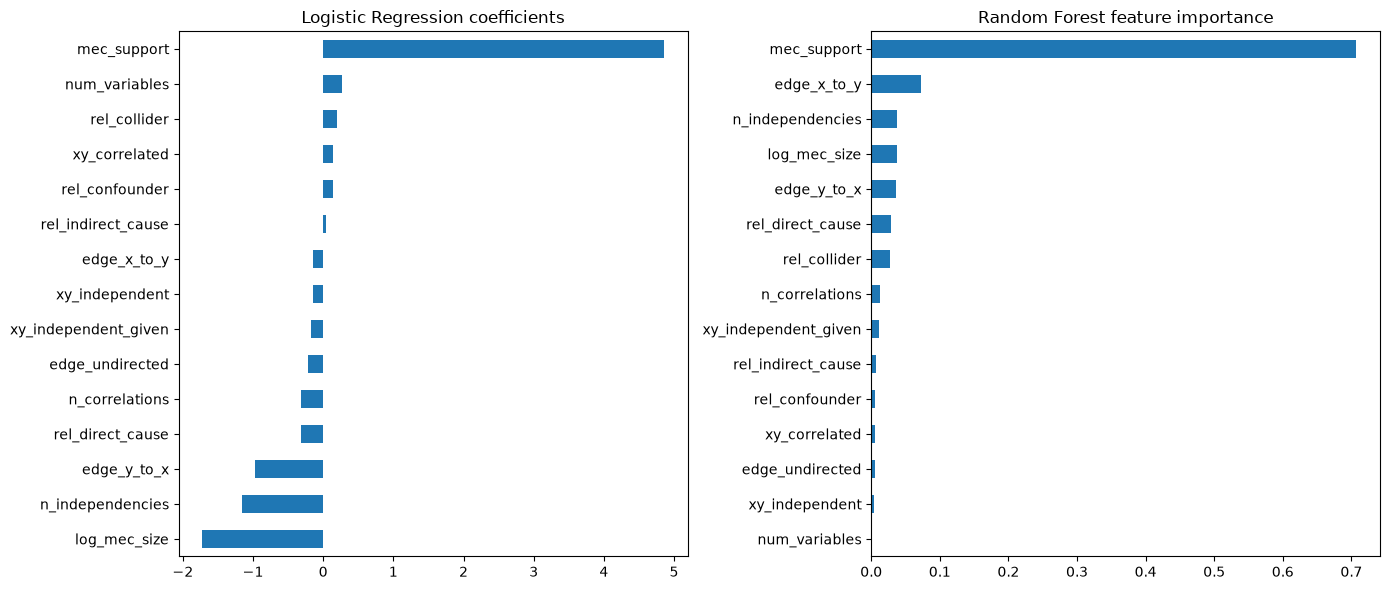

In [15]:
# ─── STEP 8: FEATURE IMPORTANCE ─────
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train_structured, y_train)
lr_coefs = pd.Series(lr.coef_[0], index=FEATURES).sort_values()

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42)
rf.fit(train[FEATURES], y_train)
rf_importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lr_coefs.plot(kind="barh", ax=axes[0], title="Logistic Regression coefficients")
rf_importance.plot(kind="barh", ax=axes[1], title="Random Forest feature importance")
plt.tight_layout()
plt.savefig("../report/figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

`mec_support` matters most: it has the largest logistic regression weight (+4.9) and 0.71 of the Random Forest
importance. Logistic regression also uses the uncertainty of the graph (`log_mec_size` and `n_independencies`
push towards "not valid") and the edge direction (`edge_y_to_x` pushes towards "not valid").

In [16]:
# ─── STEP 9: SAVE AS CSV ─────
columns = ["premise_id", "split", "premise", "hypothesis", "label", "template", "relation", "x", "y"] + FEATURES
data[columns].to_csv("../data/processed/features.csv", index=False)